<a id="chapter-09"></a>

# Chapter 09 · Ways to Speed Up RL / RL 加速方法

[← 学习索引](../README.md) · [项目主页](../../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 区分采样瓶颈与训练瓶颈
- 理解 batch、向量环境与多进程
- 用测量而不是直觉做优化

**开始前最好已经会：**

- 能运行并计时 PyTorch 代码
- 理解 batch 前向
- 知道 CPU/GPU 和进程的基本区别


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Why speed matters / baseline | 时间预算与基准 | 详细 |
| PyTorch computation graph | 无用梯度与 detach | 详细 |
| Several environments | 批量环境 | 详细 |
| Playing and training in separate processes | 生产者/消费者架构 | 详细 |
| Tweaking wrappers | 预处理位置与复制成本 | 详细 |
| Benchmark results | 实验设计与解释 | 完整 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

训练慢时，到底该增加环境、换 GPU，还是减少日志？不先测量瓶颈，优化往往只是移动等待位置。

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

吞吐量由环境采样、预处理、主机到设备传输、前向/反向和日志共同决定。并行只对当前瓶颈有效。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $T_{env}$ | 环境采样时间 | step、模拟、预处理 |
| $T_{net}$ | 网络计算时间 | 前向与反向 |
| throughput | 单位时间 environment steps | 工程速度指标 |
| sample efficiency | 达到回报所需样本数 | 算法效率指标 |
| wall-clock | 达到目标回报的实际时间 | 最终常用指标 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. 先写出时间预算

串行循环近似为

$$T_{step}=T_{env}+T_{prep}+T_{transfer}+T_{net}+T_{log}$$

吞吐量约为 $1/T_{step}$。优化某一项的收益受其他项限制。

### 2. Amdahl 定律提醒我们上限

若可并行部分比例为 $p$，使用 $N$ 个 worker 的理论加速上限：

$$S(N)=\frac1{(1-p)+p/N}$$

若只有 60% 时间在环境，哪怕环境并行到无限快，总加速也不超过 $1/(1-0.6)=2.5$ 倍。

### 3. batching 为什么有效

逐样本调用网络重复产生 Python、kernel launch 和内存访问开销。batch 把相同矩阵运算合并，使硬件并行单元得到更充分利用。但 batch 太大会增加延迟并让策略数据更旧。

### 4. 工程速度不等于学习速度

最终比较应是达到相同评估回报的 wall-clock，而不是只看 FPS。一个 FPS 更高但样本效率下降的版本可能更慢收敛。


## 4. 手算一个最小例子


假设一次迭代：环境 60 ms、网络 30 ms、其他 10 ms，总计 100 ms。把网络加速 3 倍后，总计 $60+10+10=80$ ms，只加速 1.25 倍，而不是 3 倍。

这说明 profiler 的第一问题应是“时间花在哪里”，不是“哪个组件听起来最昂贵”。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### 吞吐量与利用率

粗略地，串行每步耗时 $T\approx T_{env}+T_{prep}+T_{net}+T_{log}$；吞吐量约为 $1/T$。若 $N$ 个环境能有效并行，环境部分可趋近 $T_{env}/N$，但通信和同步开销会增长。

训练时关注：environment steps/s、updates/s、GPU utilization、等待队列长度，以及达到目标回报所需的 wall-clock time。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| 逐样本网络调用 | `[net(row[None]) for row in x]` | 大量小调用 |
| batch 网络调用 | `net(x)` | 一次矩阵批处理 |
| $T$ | `time.perf_counter()` 差值 | 墙钟时间 |
| 正确性 | `torch.allclose(loop_out, batch_out)` | 优化前后先验证等价 |
| 吞吐量 | steps / elapsed seconds | 应在完整训练管线测量 |

**从公式过渡到代码时：**下面比较逐样本前向和批量前向。微基准只解释方向，真实结论要在完整训练中用 profiler 验证。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import time
import torch
from torch import nn

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(128, 256), nn.ReLU(), nn.Linear(256, 8)).eval()
x = torch.randn(2048, 128)

with torch.no_grad():
    t0 = time.perf_counter()
    loop_out = torch.cat([net(row[None]) for row in x])
    t_loop = time.perf_counter() - t0
    t0 = time.perf_counter()
    batch_out = net(x)
    t_batch = time.perf_counter() - t0

print({"loop_s": round(t_loop, 4), "batch_s": round(t_batch, 4),
       "same": torch.allclose(loop_out, batch_out, atol=1e-6)})


{'loop_s': 0.0527, 'batch_s': 0.0032, 'same': True}


### 怎样读运行结果

通常 batch 前向更快，但小规模 CPU 测量可能波动。单次结果不能作为可靠 benchmark；应 warm-up、多次重复、取中位数，并在目标硬件测量。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
建立 baseline：固定算法、seed 集合、硬件与评估协议
profile 得到 env/preprocess/transfer/forward/backward/log 时间
按瓶颈选择一种改动：
  - 网络小调用多 → batching
  - 环境慢 → vector env / 多进程 actor
  - 图像传输重 → actor 侧预处理或共享内存
  - 梯度图过大 → target/no-action 路径 no_grad
每次只改一项，确认数值结果等价
比较 steps/s、updates/s、达到相同回报的 wall-clock
```


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
def amdahl_speedup(parallel_fraction, workers):
    return 1.0 / ((1.0 - parallel_fraction) + parallel_fraction / workers)

for workers in (1, 2, 4, 16, 10_000):
    print(workers, round(amdahl_speedup(0.6, workers), 3))
print("theoretical ceiling:", 1 / (1 - 0.6))


1 1.0
2 1.429
4 1.818
16 2.286
10000 2.5
theoretical ceiling: 2.5


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`00_slow_grads.py`](../../Chapter09/00_slow_grads.py) | 慢梯度示例 | 识别不必要 computation graph |
| [`01_baseline.py`](../../Chapter09/01_baseline.py) | baseline trainer | 所有优化的对照 |
| [`02_n_envs.py`](../../Chapter09/02_n_envs.py) | 多环境采样 | 观察 batch/等待变化 |
| [`03_parallel.py`](../../Chapter09/03_parallel.py) | 并行 actor/trainer | 队列与进程边界 |
| [`04_wrappers_parallel.py`](../../Chapter09/04_wrappers_parallel.py) | worker 侧 wrappers | 减少跨进程数据量 |
| [`04_wrappers_n_env.py`](../../Chapter09/04_wrappers_n_env.py) | 非并行对照 | 隔离 wrapper 优化收益 |

<details>
<summary>为什么按这个顺序读</summary>

并行版本应沿队列追踪数据：worker 持有环境和 actor 网络快照，产生 experience；trainer 消费 batch 并更新主网络；参数同步频率控制策略陈旧度。图像若在预处理前跨进程传输，IPC 成本可能吞掉并行收益。比较 benchmark 时同时记录 CPU 核数、环境数、batch、同步频率和评估回报。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**并行环境数增加后的成功经验累积速度

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


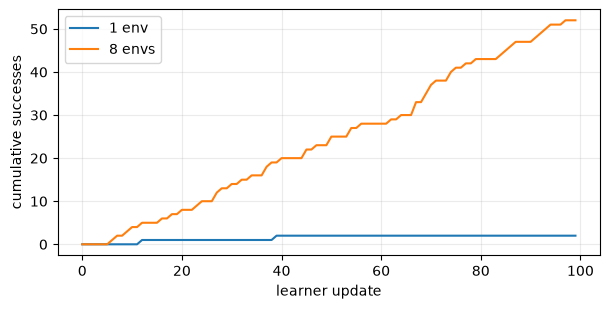

final successes: 2 52


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


rng = np.random.default_rng(9)

def vector_training(n_envs, updates=100):
    positions = np.zeros(n_envs, dtype=int)
    successes, total = [], 0
    skill = 0.55
    for update in range(updates):
        move_right = rng.random(n_envs) < skill
        positions += np.where(move_right, 1, -1)
        positions = np.clip(positions, 0, 5)
        reached = positions == 5
        total += reached.sum()
        positions[reached] = 0
        skill = min(0.9, skill + 0.002 * reached.sum())
        successes.append(total)
    return successes

one, eight = vector_training(1), vector_training(8)
plt.figure(figsize=(7, 3.2)); plt.plot(one, label="1 env"); plt.plot(eight, label="8 envs")
plt.xlabel("learner update"); plt.ylabel("cumulative successes"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("final successes:", one[-1], eight[-1])


### 曲线怎么读

按 learner update 计，更多环境通常更快收集成功经验；但真实系统还要同时看 samples/s、GPU utilization 与 policy lag，环境数不是越多越好。

### 调参过程：一次只改变一个因素

- 先测单环境 samples/s 和 GPU 利用率，找到瓶颈。
- 逐步增加环境数或 worker 数，记录吞吐和回报随 wall-clock 的变化。
- 吞吐不再增加或 policy lag 变大时停止扩容。

### 失败案例复盘

- 只按 gradient step 比较，忽略各方案消耗的环境样本不同。
- worker 使用过旧参数，吞吐上升但样本质量下降。
- 多进程重复随机种子，收集到高度相关轨迹。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 先记录 baseline 的回报曲线和 wall-clock，再优化。
- 多进程要避免每步传大图像；尽量在 worker 侧预处理。
- 更高 FPS 不等于更快收敛，算法的样本效率同样重要。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把 batch 大小换成 32、512、8192，重复多次取中位数；解释为何非常小的计时不可靠。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

可靠微基准应先 warm-up，重复多次并取中位数；batch=32 可能被 Python/调度开销主导，512 更能利用矩阵并行，8192 可能受内存带宽或缓存限制。最终仍需在完整训练中比较 wall-clock 学习曲线。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 先测量、再优化、最后重新测量。
- Amdahl 定律决定局部优化的收益上限。
- batching、向量环境和多进程针对不同瓶颈。
- 报告 wall-clock 学习曲线，而不只报告 FPS。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**如果 GPU 利用率很低，是否能直接断定网络太小？

<details>
<summary>展开答案</summary>

不能。GPU 可能在等待环境、数据传输、Python 调度或同步；需要 profiler 和时间分解确定真正瓶颈。
</details>


## 17. 与前后章节连接

第 10 章展示另一个常见瓶颈：环境与数据正确性往往比网络算力更重要。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

可进一步使用 pinned memory、异步采样、mixed precision、`torch.compile` 与共享内存，但每项都应以端到端指标验证。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-09) · [← 学习索引](../README.md)
